In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.tree import plot_tree

##### Data preperation

In [17]:
# Check the data
df = pd.read_csv("car_fuel_efficiency_2026.csv")
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [18]:
# Check the total of missing values
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [19]:
# Replace missing values
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns

df[num_cols] = df[num_cols].fillna(0.0)
df[cat_cols] = df[cat_cols].fillna("NA")

# Check the total of missing values
df.isnull().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

##### EDA

In [20]:
# Size and dtypes
df.shape                                       # number of rows and columns
df.info()                                      # dtypes and non-null counts

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           10000 non-null  int64  
 1   origin               10000 non-null  object 
 2   fuel_type            10000 non-null  object 
 3   drivetrain           10000 non-null  object 
 4   num_doors            10000 non-null  int64  
 5   engine_displacement  10000 non-null  int64  
 6   num_cylinders        10000 non-null  int64  
 7   horsepower           10000 non-null  float64
 8   vehicle_weight       10000 non-null  int64  
 9   acceleration         10000 non-null  float64
 10  fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(3), int64(5), object(3)
memory usage: 859.5+ KB


In [21]:
# Statistics
df.describe()                                  # summary statistics for numerical features
df.nunique()                                   # number of unique values per feature
df.duplicated().sum()                          # number of duplicate rows
df[cat_cols].describe()                        # count, unique, top, freq for categorical features

,origin,fuel_type,drivetrain
count,10000,10000,10000
unique,3,3,3
top,USA,Gasoline,Front-wheel drive
freq,4202,6913,5519


array([[<Axes: title={'center': 'model_year'}>,
        <Axes: title={'center': 'num_doors'}>,
        <Axes: title={'center': 'engine_displacement'}>],
       [<Axes: title={'center': 'num_cylinders'}>,
        <Axes: title={'center': 'horsepower'}>,
        <Axes: title={'center': 'vehicle_weight'}>],
       [<Axes: title={'center': 'acceleration'}>,
        <Axes: title={'center': 'fuel_efficiency_mpg'}>, <Axes: >]],
      dtype=object)

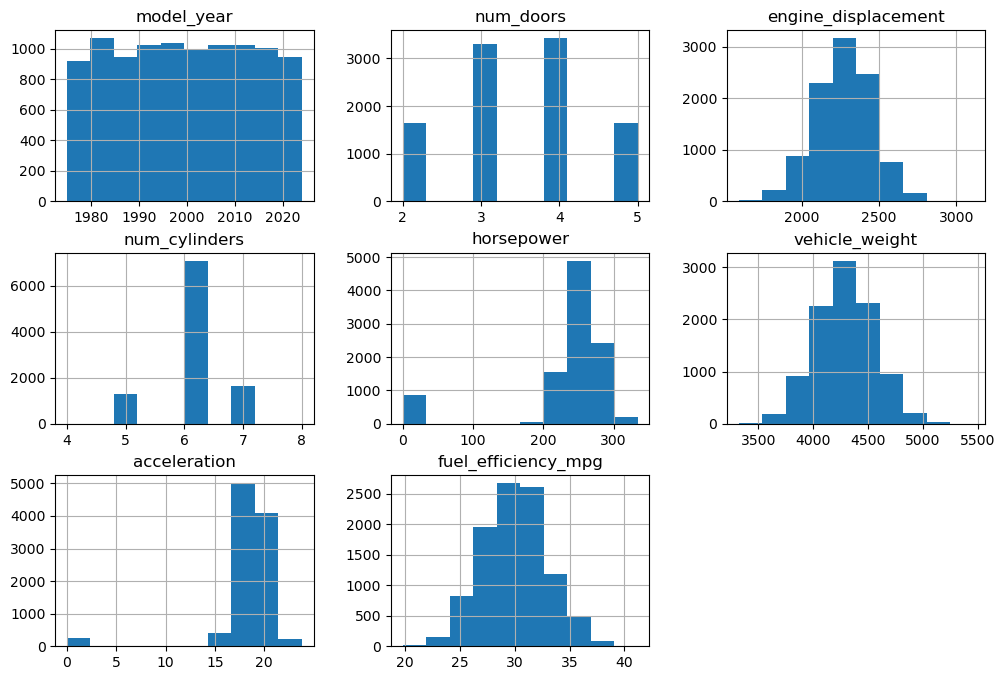

In [22]:
# Distributions
df[num_cols].hist(figsize=(12, 8))             # distributions of numerical features

In [27]:
# Split the data
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [28]:
# Get the target-values
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [ ]:
# Use one hot encoding to change the categorical variables
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(df_train.to_dict(orient="records"))
X_val = dv.transform(df_val.to_dict(orient="records"))
X_test = dv.transform(df_test.to_dict(orient="records"))

##### Question 1

In [35]:
# Train the decision tree classifier with one max_depth
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



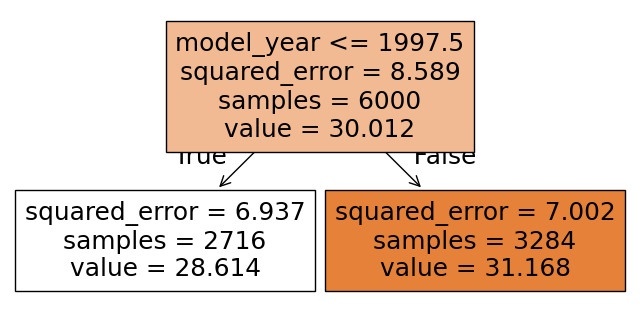

In [37]:
# Plot the tree 
plt.figure(figsize=(8, 4))
plot_tree(dt, feature_names=list(dv.get_feature_names_out()), filled=True)
plt.show()